# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

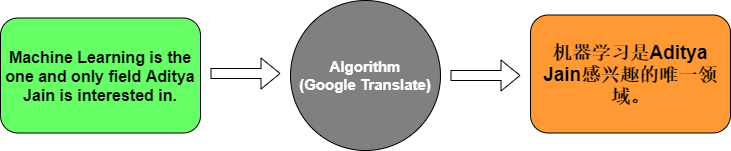

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [2]:
#!pip install tensorflow

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [4]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [6]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [7]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.0000e+00 - loss: 2.4857

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 2.4857 - val_accuracy: 0.0000e+00 - val_loss: 2.4892


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5714 - loss: 2.4748

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5714 - loss: 2.4748 - val_accuracy: 0.0000e+00 - val_loss: 2.4911


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.7143 - loss: 0.5793 - val_accuracy: 0.0000e+00 - val_loss: 5.3599


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.7143 - loss: 1.9171

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.7143 - loss: 1.9171


Test Accuracy: 0.7142857313156128


In [8]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step


Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers:**

1. **What does the Embedding layer do to a word index?** It changes the word's number into a list of numbers (a vector) that the model learns. Words used in similar ways get similar vectors.
3. **What is the role of the Encoder LSTM?** It reads the English sentence word by word and turns it into one vector that holds the sentence's meaning.
5. **What does the Decoder LSTM do?** It takes that vector and uses it to produce the French sentence, one position at a time.
8. **Why do we use `softmax` in the final layer?** It gives a probability for every French word, and the probabilities add up to 1. Then we choose the word with the highest probability.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [9]:
import time
import pandas as pd
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

tf.keras.utils.set_random_seed(42)

N_PAIRS = 30000     # subset of the 175k pairs so that training fits on a CPU
MAX_ENG_WORDS = 7
MAX_FRN_WORDS = 9
MAX_MINUTES = 15    # training stops after this time limit

df = pd.read_csv("dataset/eng_-french.csv")
df.columns = ["english", "french"]
print("All pairs:", len(df))

def clean(text):
    return text.replace("\u00a0", " ").replace("\u202f", " ").replace("’", "'").lower().strip()

df["english"] = df["english"].map(clean)
df["french"] = df["french"].map(clean)

# Keep short sentences, with one translation for each English sentence so that
# the same sentence can't appear in both the training and the test set
short = df[(df["english"].str.split().str.len() <= MAX_ENG_WORDS) & (df["french"].str.split().str.len() <= MAX_FRN_WORDS)]
short = short.drop_duplicates("english").sample(n=N_PAIRS, random_state=42)
print("Pairs used:", len(short))

eng_train_text, eng_test_text, frn_train_text, frn_test_text = train_test_split(
    short["english"].tolist(), short["french"].tolist(), test_size=0.1, random_state=42)
print("Train:", len(eng_train_text), "Test:", len(eng_test_text))

All pairs: 175621


Pairs used: 30000
Train: 27000 Test: 3000


In [10]:
# Fit the tokenizers on the training set only; unseen test words become <unk>
tok_eng = Tokenizer(oov_token="<unk>")
tok_frn = Tokenizer(oov_token="<unk>")
tok_eng.fit_on_texts(eng_train_text)
tok_frn.fit_on_texts(frn_train_text)

eng_vocab = len(tok_eng.word_index) + 1
frn_vocab = len(tok_frn.word_index) + 1
print("English vocabulary:", eng_vocab, "French vocabulary:", frn_vocab)

eng_seq_train = tok_eng.texts_to_sequences(eng_train_text)
frn_seq_train = tok_frn.texts_to_sequences(frn_train_text)
eng_len = max(map(len, eng_seq_train))
frn_len = max(map(len, frn_seq_train))

# English is padded at the start so the encoder ends on real words; French is padded at the end
X_train = pad_sequences(eng_seq_train, maxlen=eng_len)
y_train = pad_sequences(frn_seq_train, maxlen=frn_len, padding="post")
X_test = pad_sequences(tok_eng.texts_to_sequences(eng_test_text), maxlen=eng_len)
y_test = pad_sequences(tok_frn.texts_to_sequences(frn_test_text), maxlen=frn_len, padding="post", truncating="post")
print("X_train:", X_train.shape, "y_train:", y_train.shape)

English vocabulary: 7207 French vocabulary: 10984


X_train: (27000, 9) y_train: (27000, 11)


In [11]:
# Same encoder-decoder design as the LSTM model above, with larger layers for the larger dataset
translator = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),
    tf.keras.layers.LSTM(256),
    tf.keras.layers.RepeatVector(frn_len),
    tf.keras.layers.LSTM(256, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation='softmax'))
])

# Ignore padding in the loss and accuracy; otherwise predicting padding would look like good accuracy
def masked_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    mask = tf.cast(y_true != 0, tf.float32)
    loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred) * mask
    return tf.reduce_sum(loss) / tf.reduce_sum(mask)

def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    mask = tf.cast(y_true != 0, tf.float32)
    correct = tf.cast(y_true == tf.cast(tf.argmax(y_pred, axis=-1), tf.int32), tf.float32) * mask
    return tf.reduce_sum(correct) / tf.reduce_sum(mask)

translator.compile(optimizer='adam', loss=masked_loss, metrics=[masked_accuracy])

class TimeLimit(tf.keras.callbacks.Callback):
    def __init__(self, minutes):
        super().__init__()
        self.seconds = minutes * 60
    def on_train_begin(self, logs=None):
        self.start = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if time.time() - self.start > self.seconds:
            print("Time limit reached")
            self.model.stop_training = True

start = time.time()
history = translator.fit(
    X_train, y_train, epochs=40, batch_size=64, validation_split=0.1, verbose=2,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
               TimeLimit(MAX_MINUTES)])
print(f"Training time: {(time.time() - start) / 60:.1f} minutes, epochs: {len(history.history['loss'])}")

Epoch 1/40


380/380 - 116s - 305ms/step - loss: 6.9433 - masked_accuracy: 0.0478 - val_loss: 6.6303 - val_masked_accuracy: 0.0564


Epoch 2/40


380/380 - 110s - 290ms/step - loss: 6.5060 - masked_accuracy: 0.0650 - val_loss: 6.5416 - val_masked_accuracy: 0.0682


Epoch 3/40


380/380 - 111s - 291ms/step - loss: 6.3992 - masked_accuracy: 0.0693 - val_loss: 6.4507 - val_masked_accuracy: 0.0682


... (9 outputs left out)

380/380 - 110s - 289ms/step - loss: 5.1108 - masked_accuracy: 0.1858 - val_loss: 5.3853 - val_masked_accuracy: 0.1952


Epoch 9/40


Time limit reached
380/380 - 113s - 297ms/step - loss: 4.7905 - masked_accuracy: 0.2123 - val_loss: 5.2112 - val_masked_accuracy: 0.2124


Training time: 17.2 minutes, epochs: 9


In [12]:
def translate_batch(sentences):
    sequences = pad_sequences(tok_eng.texts_to_sequences(sentences), maxlen=eng_len)
    predicted = np.argmax(translator.predict(sequences, verbose=0), axis=-1)
    return tok_frn.sequences_to_texts(predicted)

# Evaluate on the unseen test set
test_loss, test_accuracy = translator.evaluate(X_test, y_test, verbose=0)
predictions = translate_batch(eng_test_text)
references = [[reference.split()] for reference in tok_frn.sequences_to_texts(y_test.tolist())]
bleu = corpus_bleu(references, [p.split() for p in predictions], smoothing_function=SmoothingFunction().method1)

print(f"Test word accuracy (ignoring padding): {test_accuracy:.3f}")
print(f"Test BLEU score: {bleu:.3f}\n")

print("Examples from the test set:")
for i in range(10):
    print(f"EN:   {eng_test_text[i]}\nREF:  {frn_test_text[i]}\nPRED: {predictions[i]}\n")

# Sentences in the style of the e-commerce use case
shop = ["this product is very good.", "where is my order?", "the price is too high.", "i like this shirt.", "thank you for your help."]
print("E-commerce examples:")
for english, french in zip(shop, translate_batch(shop)):
    print(f"EN:   {english}\nPRED: {french}\n")

Test word accuracy (ignoring padding): 0.214
Test BLEU score: 0.009

Examples from the test set:
EN:   i've tried to talk to tom.
REF:  j'ai essayé de parler à tom.
PRED: j'ai suis à tom tom tom tom tom tom tom tom

EN:   i really missed you.
REF:  vous m'avez vraiment manqué.
PRED: je suis te vous toi toi toi toi toi toi toi

EN:   i'm not interested in your problems.
REF:  je ne suis pas intéressé par tes problèmes.
PRED: je ne pas pas de de de de de de de

EN:   there's something i wish to say.
REF:  j'ai quelque chose à dire.
PRED: il est que que que que faire faire faire faire faire

EN:   now i remember.
REF:  maintenant je me rappelle.
PRED: puis je que je je chose chose chose chose chose chose

EN:   he did not accept my apologies.
REF:  il n'a pas accepté mes excuses.
PRED: il n'y pas pas de de la la la la la

EN:   who made the doll?
REF:  qui a fabriqué la poupée ?
PRED: tom est la la la la la la la la la

EN:   i come from a humble background.
REF:  je viens d'un milieu mod

EN:   this product is very good.
PRED: cette est est très très une une une n'est n'est n'est

EN:   where is my order?
PRED: quel sont les les les les les les les les les

EN:   the price is too high.
PRED: le est est est de de de de de de de

EN:   i like this shirt.
PRED: j'aime le la la la la la la la la la

EN:   thank you for your help.
PRED: as vous les vous vous les les les les les les



**Result:** The model works from start to finish, but its translations are not good enough for the company to use.

- **Data:** I used 30,000 short sentence pairs out of about 175,000. 90% were for training and 10% for testing.
- **Training:** It ran for 9 epochs in 17.2 minutes on a CPU. It stopped at the time limit while it was still improving.
- **Test results:** Word accuracy was 21.4% (not counting padding) and the BLEU score was 0.009.

**What the output shows:** The first words are sometimes close, like "je ne ..." for "i didn't understand." and "j'aime ..." for "i like this shirt.". After that, it mostly repeats one word.

**Why the results are weak:**

1. Training time was too short.
2. The loss ignores padding, so the model never learned where a sentence ends. It keeps adding words until the maximum length. An end-of-sentence token would fix this.
3. The model squeezes the whole sentence into one vector, which loses information. Adding attention would help.
4. The dataset has everyday sentences, not product listings or reviews, so the company would also need shopping data.

**To improve it:** the company should train for longer on a GPU with all the data and make these fixes, or use a ready-made pretrained translation model.